<a href="https://colab.research.google.com/github/xianyummy/C-projects/blob/main/lab06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

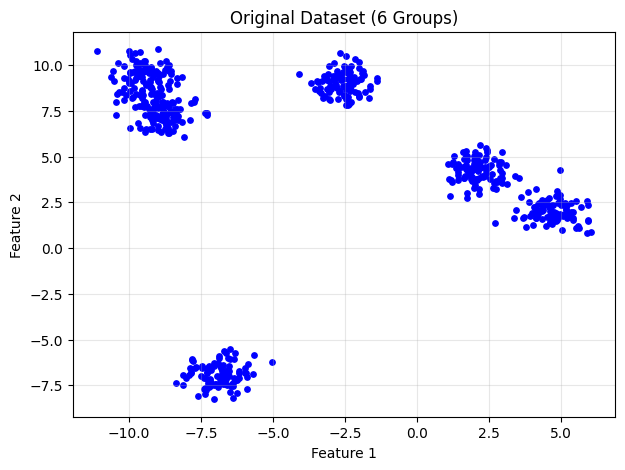

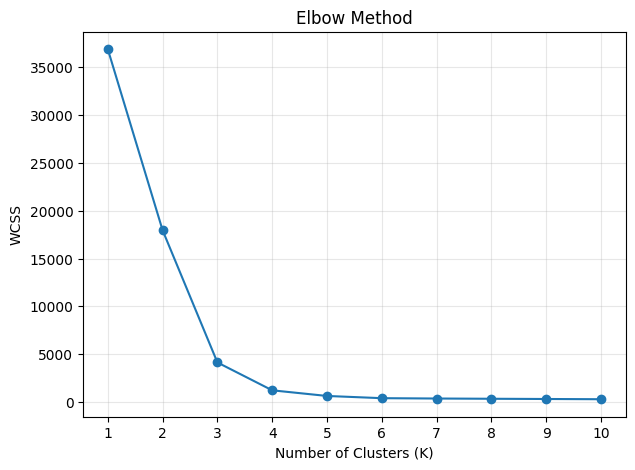

K = 2, WCSS = 17952.70
K = 4, WCSS = 1225.15
K = 6, WCSS = 402.92


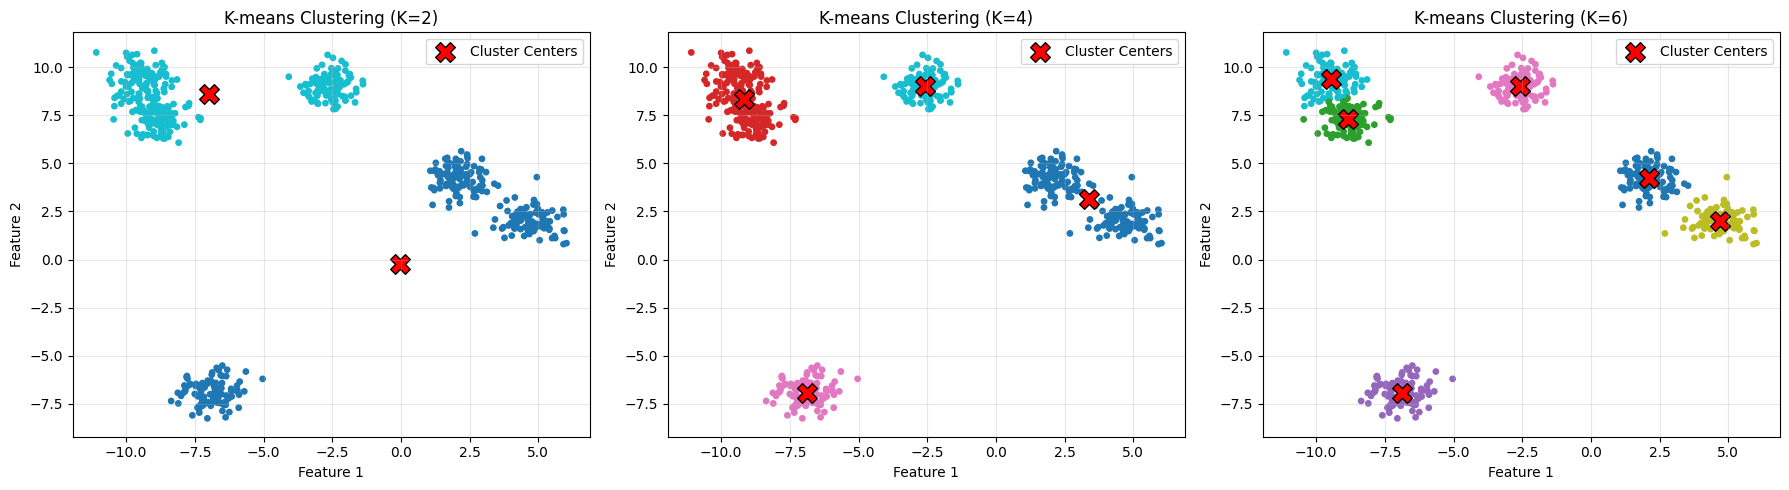

In [1]:

# ============================================================
# Lab 06 - Question 1: K-means Clustering
# 題目：產生六群資料，使用 K-means 分別進行 K=2、4、6 分群
# ============================================================

# 1. 匯入所需套件
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans


# ============================================================
# 2. 產生六群測試資料
# ============================================================

# n_samples：總資料數量
# centers：原始資料的群數
# cluster_std：每群資料的分散程度
# random_state：固定亂數種子，確保每次執行結果一致

X, y = make_blobs(
    n_samples=600,
    centers=6,
    cluster_std=0.6,
    random_state=42
)

# 繪製原始資料分布
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=15, color="blue")
plt.title("Original Dataset (6 Groups)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 3. Elbow Method：觀察不同 K 值的 WCSS
# ============================================================

# WCSS：群內平方和
# WCSS 越小，表示資料點與所屬群中心的距離越小

wcss = []

# 測試 K=1 到 K=10
for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        max_iter=300,
        n_init=10,
        random_state=42
    )

    # 訓練 K-means 模型
    kmeans.fit(X)

    # 儲存每個 K 值對應的 WCSS
    wcss.append(kmeans.inertia_)

# 繪製 Elbow Method 曲線
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 4. K-means 分群實驗：K=2、4、6
# ============================================================

# 設定題目要求的三種群數
k_values = [2, 4, 6]

# 建立三張並排的分群結果圖
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, k in enumerate(k_values):

    # 建立 K-means 模型
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        max_iter=300,
        n_init=10,
        random_state=42
    )

    # 訓練模型並取得每筆資料的群集標籤
    labels = kmeans.fit_predict(X)

    # 取得分群中心座標
    centers = kmeans.cluster_centers_

    # 使用不同顏色顯示各群資料
    axes[i].scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="tab10",
        s=15
    )

    # 使用紅色 X 標記群集中心
    axes[i].scatter(
        centers[:, 0],
        centers[:, 1],
        c="red",
        marker="X",
        s=200,
        edgecolors="black",
        label="Cluster Centers"
    )

    # 設定圖表標題與座標軸
    axes[i].set_title(f"K-means Clustering (K={k})")
    axes[i].set_xlabel("Feature 1")
    axes[i].set_ylabel("Feature 2")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

    # 顯示各 K 值的 WCSS
    print(f"K = {k}, WCSS = {kmeans.inertia_:.2f}")

# 調整圖表間距並顯示
plt.tight_layout()
plt.show()


Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Training samples: 120
Testing samples: 30
K =  1 | Train Accuracy = 1.0000 | Test Accuracy = 0.9667
K =  2 | Train Accuracy = 0.9750 | Test Accuracy = 0.9333
K =  3 | Train Accuracy = 0.9583 | Test Accuracy = 1.0000
K =  4 | Train Accuracy = 0.9583 | Test Accuracy = 1.0000
K =  5 | Train Accuracy = 0.9667 | Test Accuracy = 1.0000
K =  6 | Train Accuracy = 0.9667 | Test Accuracy = 0.9667
K =  7 | Train Accuracy = 0.9750 | Test Accuracy = 0.9667
K =  8 | Train Accuracy = 0.9750 | Test Accuracy = 0.9667
K =  9 | Train Accuracy = 0.9750 | Test Accuracy = 1.0000
K = 10 | Train Accuracy = 0.9750 | Test Accuracy = 1.0000
K = 11 | Train Accuracy = 0.9750 | Test Accuracy = 0.9667
K = 12 | Train Accuracy = 0.9667 | Test Accuracy = 0.9667
K = 13 | Train Accuracy = 0.9750 | Test Accuracy = 0.9667
K = 14 | Train Accuracy = 0.9833 | Test Accuracy = 0.9667
K = 15 | Train Accuracy = 0.9750 | Test Accuracy = 0.9667
K = 16 | Train Accu

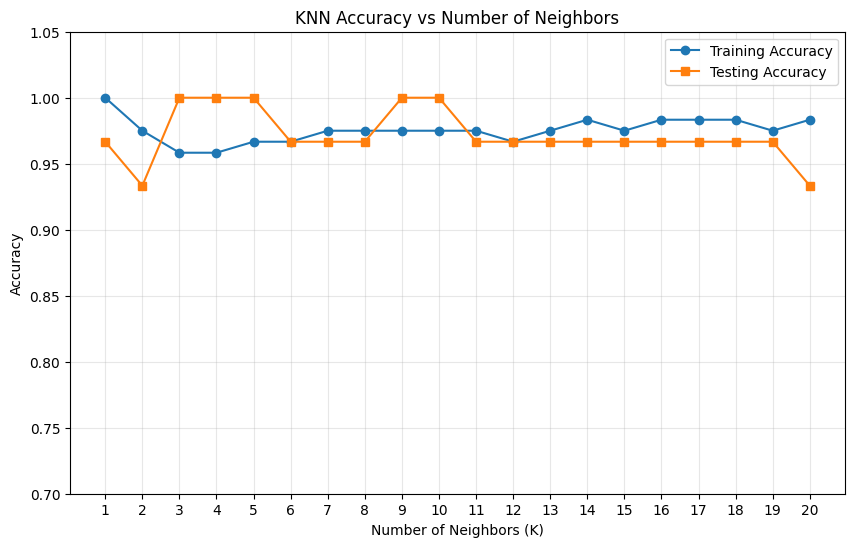


========== KNN Experiment Result ==========
Best K: 3
Best Test Accuracy: 1.0000
Best Test Accuracy (%): 100.00%


In [2]:

# ============================================================
# Lab 06 - Question 2: K-Nearest Neighbors (KNN)
# 題目：Evaluate the knn.score by n_neighbors
# 目的：比較不同鄰居數量 K 對 KNN 分類準確率的影響
# ============================================================

# 1. 匯入所需套件
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


# ============================================================
# 2. 載入 Iris 鳶尾花資料集
# ============================================================

# Iris 資料集包含 150 筆資料、3 種花卉類別
# 每筆資料有 4 個特徵：
# Sepal Length、Sepal Width、Petal Length、Petal Width

iris = load_iris()

# X：輸入特徵
# y：對應的花卉類別標籤
X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)


# ============================================================
# 3. 分割訓練資料與測試資料
# ============================================================

# 80% 作為訓練資料，20% 作為測試資料
# stratify=y：維持各類別在訓練集與測試集的比例
# random_state=42：固定亂數種子，確保結果可重現

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 4. 測試不同的 n_neighbors
# ============================================================

# 測試 K = 1 到 20
k_values = range(1, 21)

train_scores = []
test_scores = []

for k in k_values:

    # 建立 KNN 分類器
    knn = KNeighborsClassifier(n_neighbors=k)

    # 使用訓練資料訓練模型
    knn.fit(X_train, y_train)

    # 計算訓練集準確率
    train_score = knn.score(X_train, y_train)

    # 計算測試集準確率
    test_score = knn.score(X_test, y_test)

    # 儲存準確率
    train_scores.append(train_score)
    test_scores.append(test_score)

    # 印出每個 K 值的結果
    print(
        f"K = {k:2d} | "
        f"Train Accuracy = {train_score:.4f} | "
        f"Test Accuracy = {test_score:.4f}"
    )


# ============================================================
# 5. 繪製 K 值與準確率的關係圖
# ============================================================

plt.figure(figsize=(10, 6))

# 訓練集準確率曲線
plt.plot(
    k_values,
    train_scores,
    marker="o",
    label="Training Accuracy"
)

# 測試集準確率曲線
plt.plot(
    k_values,
    test_scores,
    marker="s",
    label="Testing Accuracy"
)

plt.title("KNN Accuracy vs Number of Neighbors")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")

plt.xticks(list(k_values))
plt.ylim(0.7, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# ============================================================
# 6. 找出測試集準確率最高的 K 值
# ============================================================

# 找出最高測試準確率的位置
best_index = np.argmax(test_scores)

best_k = list(k_values)[best_index]
best_score = test_scores[best_index]

print("\n========== KNN Experiment Result ==========")
print(f"Best K: {best_k}")
print(f"Best Test Accuracy: {best_score:.4f}")
print(f"Best Test Accuracy (%): {best_score * 100:.2f}%")
print("===========================================")


Dataset shape: (150, 2)
Classes: ['setosa' 'versicolor' 'virginica']


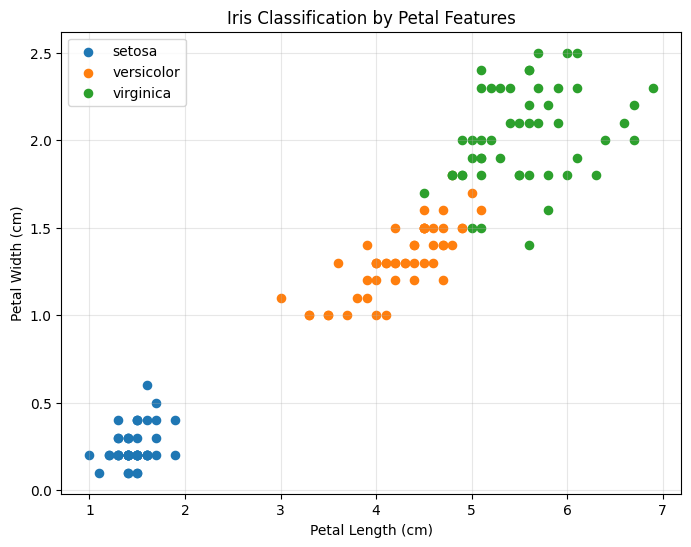

Training samples: 120
Testing samples: 30

========== KNN Classification Result ==========
Number of Neighbors (K): 5
Training Accuracy: 0.9583
Testing Accuracy: 0.9667
Testing Accuracy (%): 96.67%


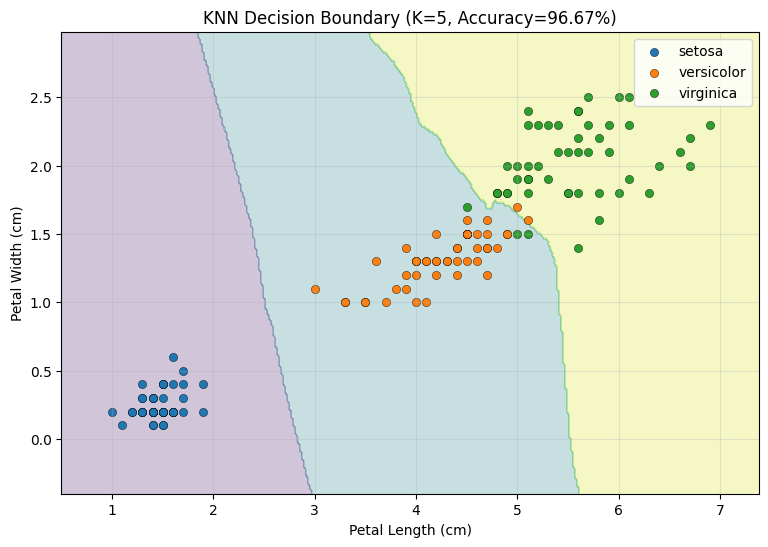


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Correct Predictions: 29
Incorrect Predictions: 1
Total Test Samples: 30


In [3]:

# ============================================================
# Lab 06 - Question 3: KNN Classification Using Petal Features
# 題目：Show categories by petal and implement KNN (show score)
# 目的：使用花瓣長度與寬度進行 Iris 分類，並顯示準確率
# ============================================================

# 1. 匯入所需套件
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix


# ============================================================
# 2. 載入 Iris 鳶尾花資料集
# ============================================================

iris = load_iris()

# Iris 資料集共有四個特徵：
# 0：Sepal Length（花萼長度）
# 1：Sepal Width（花萼寬度）
# 2：Petal Length（花瓣長度）
# 3：Petal Width（花瓣寬度）

# 本題只選擇 Petal Length 與 Petal Width
X = iris.data[:, 2:4]

# y 為花卉類別標籤（0、1、2）
y = iris.target

# 三種鳶尾花名稱
class_names = iris.target_names

print("Dataset shape:", X.shape)
print("Classes:", class_names)


# ============================================================
# 3. 繪製 Petal 特徵的原始分類散佈圖
# ============================================================

plt.figure(figsize=(8, 6))

# 分別繪製三種鳶尾花
for i in range(3):

    # 取得目前類別的資料
    class_data = X[y == i]

    plt.scatter(
        class_data[:, 0],
        class_data[:, 1],
        label=class_names[i],
        s=35
    )

plt.title("Iris Classification by Petal Features")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 4. 分割訓練資料與測試資料
# ============================================================

# 80% 作為訓練集，20% 作為測試集
# stratify=y：維持各類別的資料比例
# random_state=42：確保結果可重現

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 5. 建立並訓練 KNN 分類模型
# ============================================================

# 設定 K=5，代表參考最近的五個鄰居
knn = KNeighborsClassifier(n_neighbors=5)

# 使用訓練資料進行模型訓練
knn.fit(X_train, y_train)

# 使用測試資料進行分類預測
y_pred = knn.predict(X_test)

# 計算訓練集準確率
train_score = knn.score(X_train, y_train)

# 計算測試集準確率
test_score = knn.score(X_test, y_test)

print("\n========== KNN Classification Result ==========")
print(f"Number of Neighbors (K): {knn.n_neighbors}")
print(f"Training Accuracy: {train_score:.4f}")
print(f"Testing Accuracy: {test_score:.4f}")
print(f"Testing Accuracy (%): {test_score * 100:.2f}%")
print("===============================================")


# ============================================================
# 6. 繪製 KNN 分類決策邊界
# ============================================================

# 設定 X 軸與 Y 軸的顯示範圍
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# 建立網格座標，用來顯示模型的分類區域
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# 將網格座標轉換為模型可預測的資料格式
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 使用 KNN 預測每個網格點的類別
Z = knn.predict(grid_points)

# 將預測結果還原成網格形狀
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))

# 繪製 KNN 分類區域
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.25,
    cmap="viridis"
)

# 繪製原始資料點
for i in range(3):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=class_names[i],
        s=35,
        edgecolors="black",
        linewidths=0.3
    )

plt.title(f"KNN Decision Boundary (K=5, Accuracy={test_score:.2%})")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 7. 顯示 Confusion Matrix（混淆矩陣）
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 顯示預測正確與錯誤的數量
correct = np.sum(y_pred == y_test)
incorrect = np.sum(y_pred != y_test)

print(f"\nCorrect Predictions: {correct}")
print(f"Incorrect Predictions: {incorrect}")
print(f"Total Test Samples: {len(y_test)}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 6.4 MB/s eta 0:00:00
Dataset shape: (800, 2)
Original number of clusters: 4


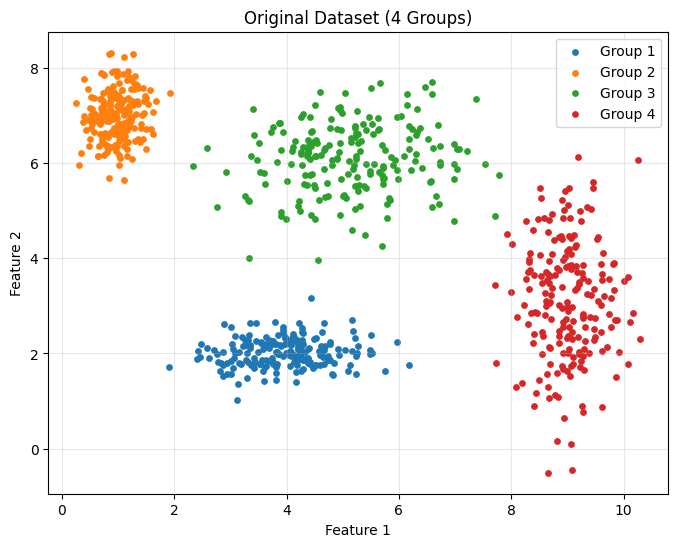

Clusters = 2, FPC = 0.7378
Clusters = 3, FPC = 0.7710
Clusters = 4, FPC = 0.8310
Clusters = 5, FPC = 0.7743
Clusters = 6, FPC = 0.7480


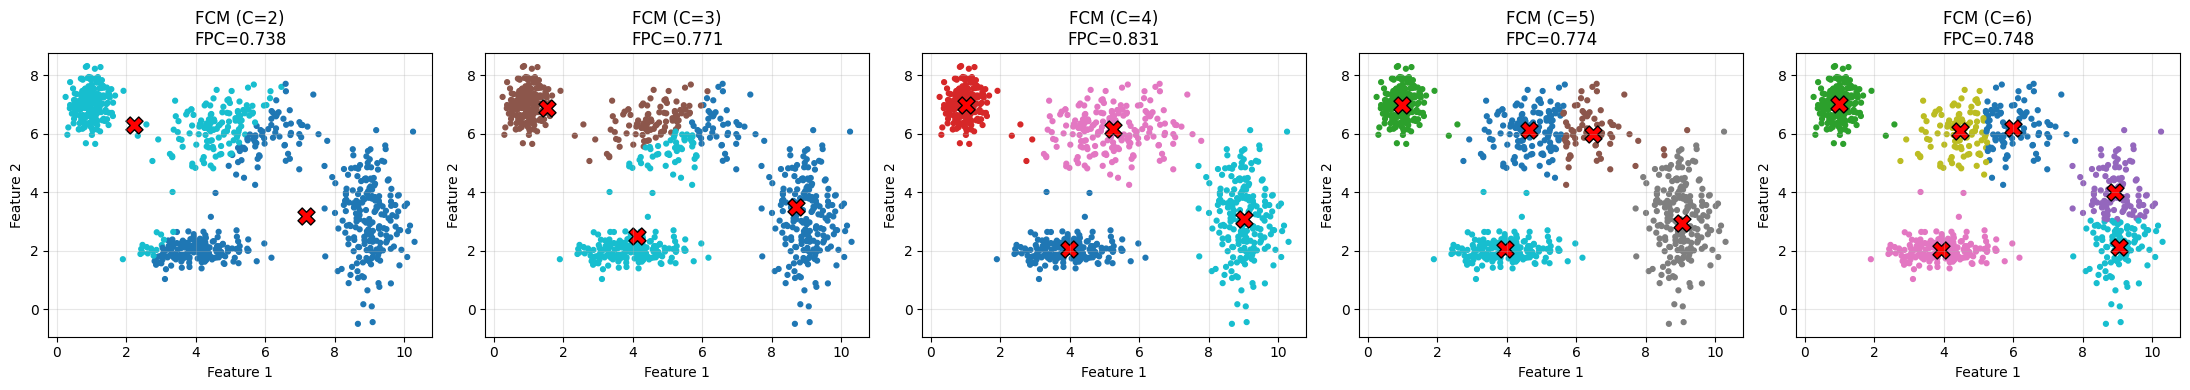

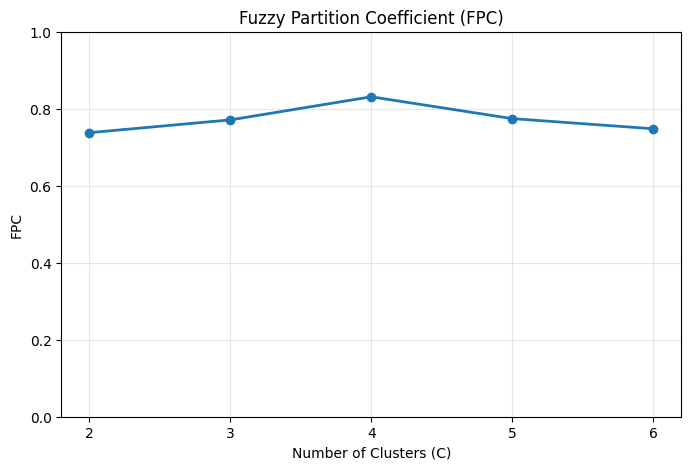

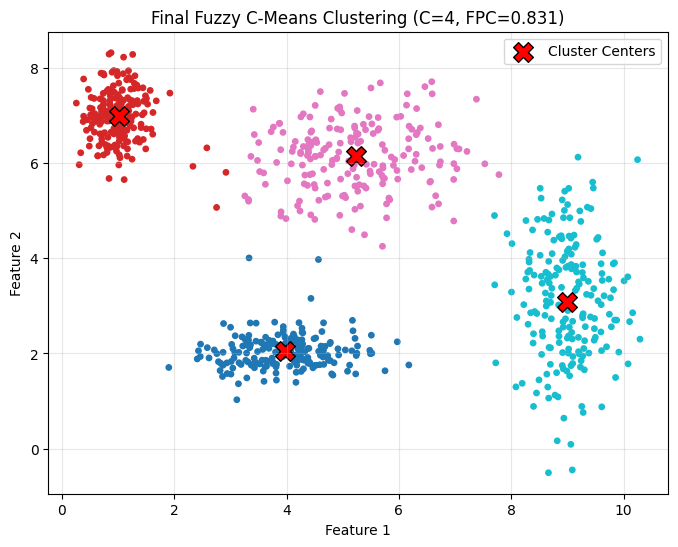


========== Fuzzy C-Means Result ==========
Number of Clusters: 4
FPC: 0.831
Cluster Centers:
[[3.97082432 2.05749691]
 [1.01477309 6.98771763]
 [5.24297451 6.14624047]
 [8.99552943 3.07457591]]


In [4]:

# ============================================================
# Lab 06 - Question 4: Fuzzy C-Means Clustering
# 題目：使用指定的四群資料，實作 Fuzzy C-Means 分群
# 目的：觀察不同群數的分群結果，並利用 FPC 評估分群品質
# ============================================================

# 1. 安裝 Fuzzy C-Means 所需套件
%pip -q install scikit-fuzzy

# 匯入套件
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz


# ============================================================
# 2. 定義老師指定的四群資料
# ============================================================

# 四個群集的中心座標 (x, y)
centers = [
    [4, 2],
    [1, 7],
    [5, 6],
    [9, 3]
]

# 每個群集在 x、y 方向的標準差
# 標準差越大，資料分布越分散
sigmas = [
    [0.8, 0.3],
    [0.3, 0.5],
    [1.1, 0.7],
    [0.5, 1.2]
]

# 固定亂數種子，確保每次執行結果一致
np.random.seed(42)

# 儲存產生的資料點及原始類別
data = []
true_labels = []

# 每群產生 200 筆資料
for i, (center, sigma) in enumerate(zip(centers, sigmas)):

    # 使用常態分布產生 x 座標
    x = np.random.normal(
        loc=center[0],
        scale=sigma[0],
        size=200
    )

    # 使用常態分布產生 y 座標
    y = np.random.normal(
        loc=center[1],
        scale=sigma[1],
        size=200
    )

    # 合併 x、y 座標
    cluster_data = np.column_stack((x, y))

    # 儲存目前群集的資料
    data.append(cluster_data)

    # 儲存原始群集標籤
    true_labels.extend([i] * 200)

# 將四群資料合併成一個資料集
X = np.vstack(data)
true_labels = np.array(true_labels)

print("Dataset shape:", X.shape)
print("Original number of clusters:", len(centers))


# ============================================================
# 3. 繪製原始四群資料分布
# ============================================================

plt.figure(figsize=(8, 6))

for i in range(4):

    # 取得第 i 群的資料
    cluster_points = X[true_labels == i]

    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        s=15,
        label=f"Group {i+1}"
    )

plt.title("Original Dataset (4 Groups)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 4. 使用 Fuzzy C-Means 進行分群
# ============================================================

# scikit-fuzzy 的 cmeans 輸入格式為 (features, samples)
# 因此需要將 X 從 (800, 2) 轉置為 (2, 800)
data_fcm = X.T

# 測試不同群數
cluster_numbers = [2, 3, 4, 5, 6]

# 儲存每個群數的 FPC
fpc_values = []

# 建立分群結果圖
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for i, c in enumerate(cluster_numbers):

    # 執行 Fuzzy C-Means
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        data_fcm,
        c=c,              # 分群數量
        m=2,              # 模糊程度參數
        error=0.005,      # 收斂誤差門檻
        maxiter=1000,     # 最大迭代次數
        seed=42           # 固定亂數種子
    )

    # u 為隸屬度矩陣
    # 每筆資料對每個群集都有一個隸屬度
    # 選擇隸屬度最高的群集作為最終分類
    labels = np.argmax(u, axis=0)

    # 儲存 FPC
    fpc_values.append(fpc)

    # 繪製分群結果
    axes[i].scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="tab10",
        s=12
    )

    # 標示 FCM 計算得到的群集中心
    axes[i].scatter(
        cntr[:, 0],
        cntr[:, 1],
        marker="X",
        s=150,
        c="red",
        edgecolors="black"
    )

    axes[i].set_title(f"FCM (C={c})\nFPC={fpc:.3f}")
    axes[i].set_xlabel("Feature 1")
    axes[i].set_ylabel("Feature 2")
    axes[i].grid(alpha=0.3)

    print(f"Clusters = {c}, FPC = {fpc:.4f}")

plt.tight_layout()
plt.show()


# ============================================================
# 5. 繪製 FPC 與群數的關係圖
# ============================================================

# FPC = Fuzzy Partition Coefficient
# FPC 越接近 1，表示分群的隸屬度越明確
# 可用來輔助選擇適當的群數

plt.figure(figsize=(8, 5))

plt.plot(
    cluster_numbers,
    fpc_values,
    marker="o",
    linewidth=2
)

plt.title("Fuzzy Partition Coefficient (FPC)")
plt.xlabel("Number of Clusters (C)")
plt.ylabel("FPC")
plt.xticks(cluster_numbers)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 6. 使用 C=4 進行最終分群
# ============================================================

# 因為原始資料設定為四群，因此另外觀察 C=4 的結果
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_fcm,
    c=4,
    m=2,
    error=0.005,
    maxiter=1000,
    seed=42
)

# 取得每筆資料隸屬度最高的群集
final_labels = np.argmax(u, axis=0)

# 顯示最終分群結果
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=final_labels,
    cmap="tab10",
    s=15
)

# 標記群集中心
plt.scatter(
    cntr[:, 0],
    cntr[:, 1],
    marker="X",
    s=200,
    c="red",
    edgecolors="black",
    label="Cluster Centers"
)

plt.title(f"Final Fuzzy C-Means Clustering (C=4, FPC={fpc:.3f})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 顯示最終實驗結果
print("\n========== Fuzzy C-Means Result ==========")
print("Number of Clusters:", 4)
print("FPC:", round(fpc, 4))
print("Cluster Centers:")
print(cntr)
print("==========================================")


Training class counts: [2033  242  125]
Testing class counts: [508  61  31]


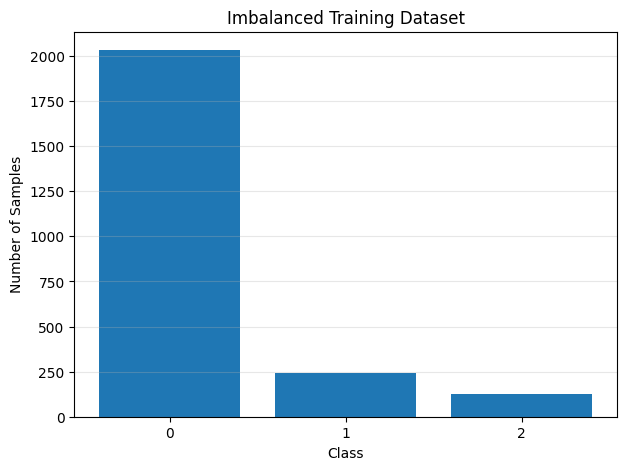


========== Original Model ==========
              precision    recall  f1-score   support

           0       0.86      1.00      0.92       508
           1       1.00      0.13      0.23        61
           2       0.00      0.00      0.00        31

    accuracy                           0.86       600
   macro avg       0.62      0.38      0.39       600
weighted avg       0.83      0.86      0.81       600

Class weights: [0.39350713 3.30578512 6.4       ]

========== Weighted Model ==========
              precision    recall  f1-score   support

           0       0.99      0.92      0.95       508
           1       0.63      0.89      0.73        61
           2       0.66      0.87      0.75        31

    accuracy                           0.92       600
   macro avg       0.76      0.89      0.81       600
weighted avg       0.94      0.92      0.92       600


========== Performance Comparison ==========
Original Accuracy: 0.8600
Weighted Accuracy: 0.9150
Original Balan

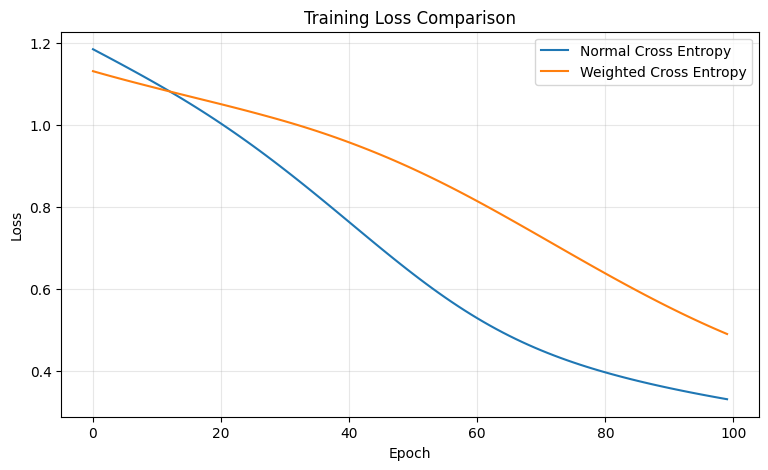

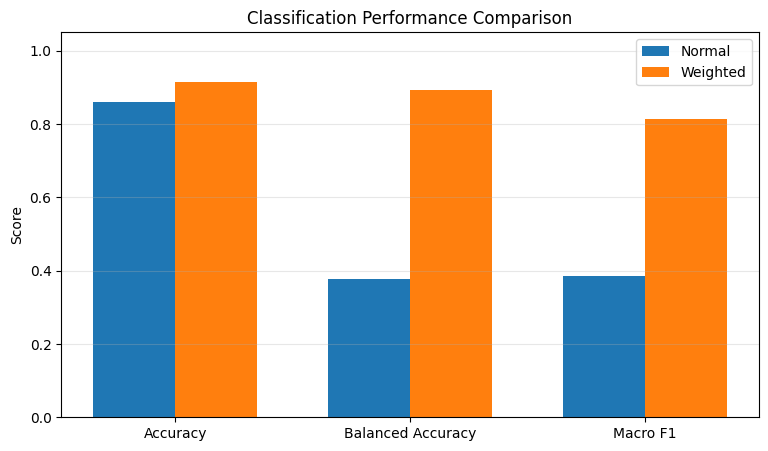

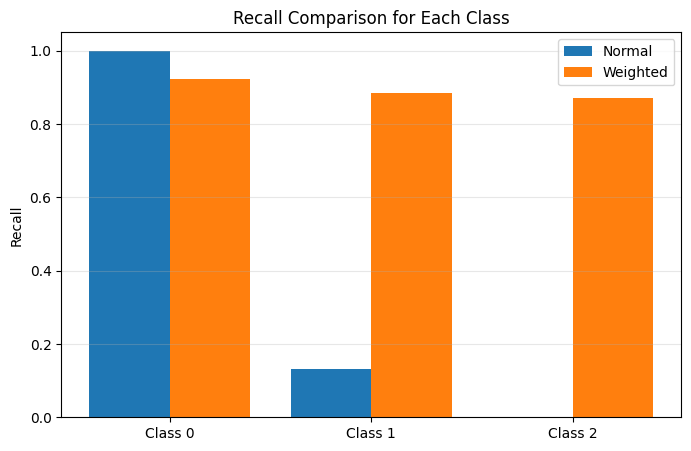

In [5]:

# ============================================================
# Lab 06 - Question 5: Imbalanced Data
# 題目：How to improve classification with imbalanced data?
# 方法：比較 Cross Entropy 與 Weighted Cross Entropy
# ============================================================

# 1. 匯入所需套件
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# 固定亂數種子，確保實驗可以重現
np.random.seed(42)
torch.manual_seed(42)


# ============================================================
# 2. 建立不平衡分類資料集
# ============================================================

# 產生三種類別，比例約為 85%、10%、5%
# 模擬真實世界中少數類別資料不足的情況

X, y = make_classification(
    n_samples=3000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_classes=3,
    n_clusters_per_class=1,
    weights=[0.85, 0.10, 0.05],
    flip_y=0.01,
    class_sep=1.0,
    random_state=42
)

# 分割訓練集與測試集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 標準化資料，避免不同特徵尺度影響訓練
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 轉換成 PyTorch Tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# 顯示各類別資料數量
class_counts = np.bincount(y_train, minlength=3)

print("Training class counts:", class_counts)
print("Testing class counts:", np.bincount(y_test, minlength=3))

# 繪製資料分布圖
plt.figure(figsize=(7, 5))
plt.bar(range(3), class_counts)
plt.title("Imbalanced Training Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(range(3))
plt.grid(axis="y", alpha=0.3)
plt.show()


# ============================================================
# 3. 建立簡單的神經網路分類模型
# ============================================================

class SimpleNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(10, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================
# 4. 定義模型訓練函式
# ============================================================

def train_model(model, criterion, epochs=100):

    optimizer = optim.Adam(model.parameters(), lr=0.001)

    loss_history = []

    for epoch in range(epochs):

        # 切換到訓練模式
        model.train()

        # 清除上一輪梯度
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(X_train_t)

        # 計算 Loss
        loss = criterion(outputs, y_train_t)

        # Backpropagation
        loss.backward()

        # 更新模型權重
        optimizer.step()

        # 記錄每一輪 Loss
        loss_history.append(loss.item())

    return loss_history


# ============================================================
# 5. 原始方法：一般 Cross Entropy
# ============================================================

# 建立原始模型
torch.manual_seed(42)
model_normal = SimpleNN()

# 一般交叉熵：各類別沒有額外權重
criterion_normal = nn.CrossEntropyLoss()

# 訓練模型
loss_normal = train_model(
    model_normal,
    criterion_normal,
    epochs=100
)

# 取得測試集預測結果
model_normal.eval()

with torch.no_grad():
    outputs_normal = model_normal(X_test_t)
    pred_normal = torch.argmax(outputs_normal, dim=1).numpy()

print("\n========== Original Model ==========")
print(classification_report(
    y_test, pred_normal,
    labels=[0, 1, 2],
    zero_division=0
))


# ============================================================
# 6. 改善方法：Weighted Cross Entropy
# ============================================================

# 計算每個類別的權重
# 類別資料越少，權重越高
# weight_i = N / (C * N_i)

total_samples = len(y_train)
num_classes = 3

class_weights = total_samples / (
    num_classes * class_counts
)

# 轉換成 PyTorch Tensor
class_weights_t = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("Class weights:", class_weights)

# 建立改善後模型
# 使用相同亂數種子，確保初始權重一致
torch.manual_seed(42)
model_weighted = SimpleNN()

# 加入類別權重的 Cross Entropy
criterion_weighted = nn.CrossEntropyLoss(
    weight=class_weights_t
)

# 訓練改善後模型
loss_weighted = train_model(
    model_weighted,
    criterion_weighted,
    epochs=100
)

# 預測測試資料
model_weighted.eval()

with torch.no_grad():
    outputs_weighted = model_weighted(X_test_t)
    pred_weighted = torch.argmax(
        outputs_weighted, dim=1
    ).numpy()

print("\n========== Weighted Model ==========")
print(classification_report(
    y_test, pred_weighted,
    labels=[0, 1, 2],
    zero_division=0
))


# ============================================================
# 7. 比較兩種模型的分類結果
# ============================================================

# 整體準確率
acc_normal = accuracy_score(y_test, pred_normal)
acc_weighted = accuracy_score(y_test, pred_weighted)

# Balanced Accuracy：各類別 Recall 的平均
bal_normal = balanced_accuracy_score(y_test, pred_normal)
bal_weighted = balanced_accuracy_score(y_test, pred_weighted)

# Macro F1：各類別 F1 的平均
f1_normal = f1_score(y_test, pred_normal, average="macro")
f1_weighted = f1_score(y_test, pred_weighted, average="macro")

print("\n========== Performance Comparison ==========")
print(f"Original Accuracy: {acc_normal:.4f}")
print(f"Weighted Accuracy: {acc_weighted:.4f}")
print(f"Original Balanced Accuracy: {bal_normal:.4f}")
print(f"Weighted Balanced Accuracy: {bal_weighted:.4f}")
print(f"Original Macro F1: {f1_normal:.4f}")
print(f"Weighted Macro F1: {f1_weighted:.4f}")


# ============================================================
# 8. 繪製訓練 Loss 曲線
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(loss_normal, label="Normal Cross Entropy")
plt.plot(loss_weighted, label="Weighted Cross Entropy")

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 注意：兩種 Loss 的權重不同
# 因此不能只根據 Loss 數值高低判斷哪個模型較好


# ============================================================
# 9. 繪製分類效能比較圖
# ============================================================

metrics = ["Accuracy", "Balanced Accuracy", "Macro F1"]

normal_values = [acc_normal, bal_normal, f1_normal]
weighted_values = [acc_weighted, bal_weighted, f1_weighted]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    normal_values,
    width,
    label="Normal"
)

plt.bar(
    x + width / 2,
    weighted_values,
    width,
    label="Weighted"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Classification Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


# ============================================================
# 10. 比較各類別 Recall
# ============================================================

def calculate_recall_per_class(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    return np.diag(cm) / np.maximum(cm.sum(axis=1), 1)

recall_normal = calculate_recall_per_class(
    y_test, pred_normal
)

recall_weighted = calculate_recall_per_class(
    y_test, pred_weighted
)

x = np.arange(3)

plt.figure(figsize=(8, 5))

plt.bar(
    x - 0.2,
    recall_normal,
    0.4,
    label="Normal"
)

plt.bar(
    x + 0.2,
    recall_weighted,
    0.4,
    label="Weighted"
)

plt.xticks(x, ["Class 0", "Class 1", "Class 2"])
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.title("Recall Comparison for Each Class")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


Training samples: 150
Validation samples: 850

Training Model A (Without Dropout)...
Training Model B (With Dropout)...


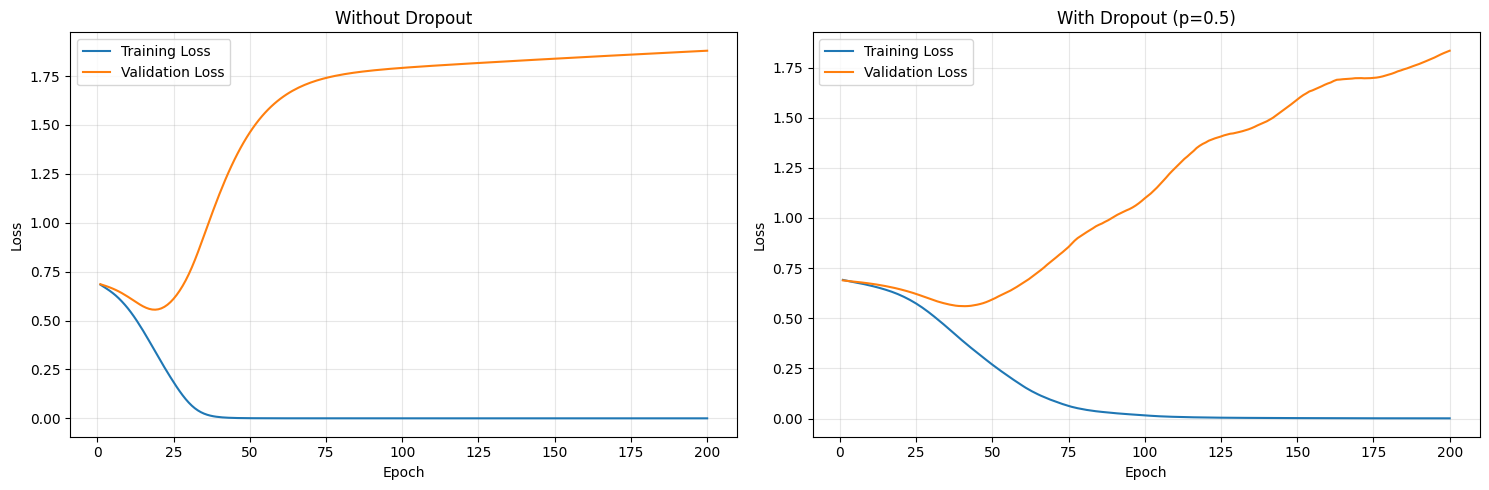

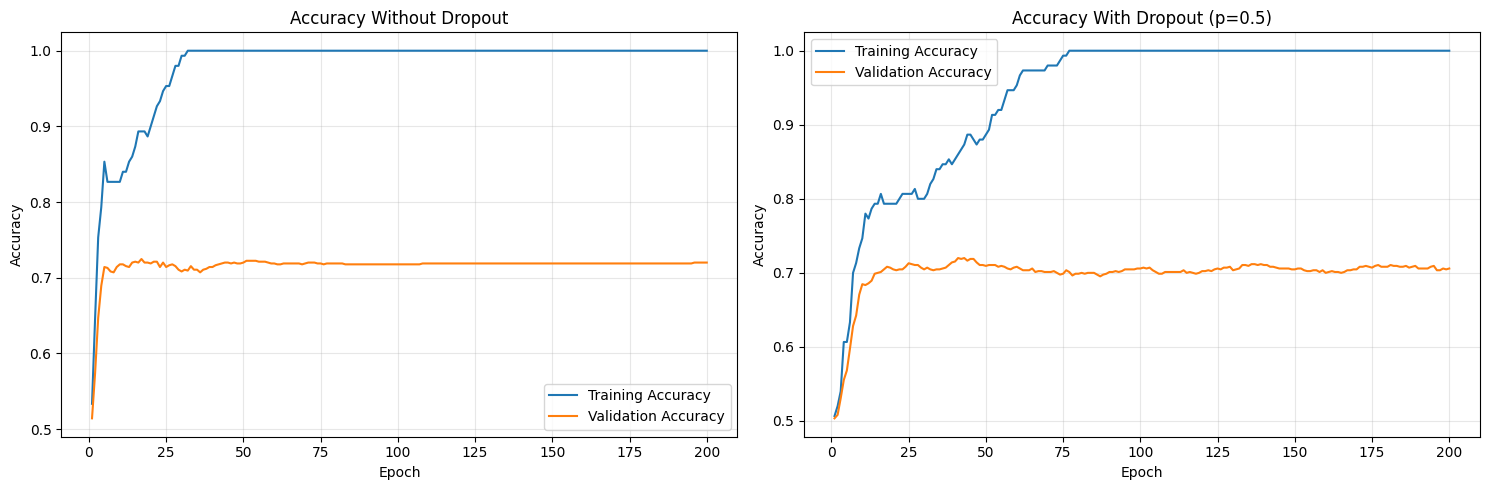


========== Final Experiment Results ==========

Model A: Without Dropout
Training Accuracy: 1.0
Validation Accuracy: 0.72
Validation Loss: 1.8794

Model B: With Dropout
Training Accuracy: 1.0
Validation Accuracy: 0.7059
Validation Loss: 1.8341

========== Best Validation Loss ==========
Without Dropout: 0.5555
With Dropout: 0.5602
Best Epoch Without Dropout: 19
Best Epoch With Dropout: 41


In [6]:

# ============================================================
# Lab 06 - Question 6: Dropout and Overfitting
# 題目：How to use dropout to improve overfitting?
# 目的：比較加入 Dropout 前後的 Loss 與 Accuracy
# ============================================================

# 1. 匯入所需套件
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# 固定亂數種子，讓實驗可以重現
np.random.seed(42)
torch.manual_seed(42)

# ============================================================
# 2. 建立容易發生 Overfitting 的資料集
# ============================================================

# 使用較少的資料與較多的特徵
# 增加模型記住訓練資料的可能性

X, y = make_classification(
    n_samples=1000,
    n_features=50,
    n_informative=10,
    n_redundant=10,
    n_classes=2,
    flip_y=0.15,
    class_sep=0.8,
    random_state=42
)

# 只使用 15% 資料進行訓練
# 其餘 85% 作為驗證資料
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    train_size=0.15,
    random_state=42,
    stratify=y
)

# 標準化資料
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

# 轉換成 PyTorch Tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


# ============================================================
# 3. 建立神經網路模型
# ============================================================

# 使用相同架構進行比較
# 差別只有是否加入 Dropout

class NeuralNetwork(nn.Module):

    def __init__(self, dropout_rate=0.0):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(50, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),

            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================
# 4. 定義模型訓練函式
# ============================================================

def train_model(model, epochs=200):

    # 使用交叉熵作為 Loss Function
    criterion = nn.CrossEntropyLoss()

    # 使用 Adam Optimizer
    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    # 儲存每個 Epoch 的實驗結果
    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # ----------------------------
        # Training Phase
        # ----------------------------

        # 啟用訓練模式
        # 此時 Dropout 會隨機將部分輸出設為 0
        model.train()

        optimizer.zero_grad()

        outputs = model(X_train_t)

        loss = criterion(outputs, y_train_t)

        loss.backward()

        optimizer.step()

        # ----------------------------
        # Evaluation Phase
        # ----------------------------

        # 切換至評估模式
        # 此時 Dropout 不會隨機關閉神經元輸出
        model.eval()

        with torch.no_grad():

            # 在相同的評估模式下計算兩組 Loss
            # 避免 Dropout 的隨機性干擾曲線比較
            train_outputs = model(X_train_t)
            val_outputs = model(X_val_t)

            train_loss = criterion(
                train_outputs, y_train_t
            )

            val_loss = criterion(
                val_outputs, y_val_t
            )

            # 計算預測類別
            train_pred = torch.argmax(
                train_outputs, dim=1
            )

            val_pred = torch.argmax(
                val_outputs, dim=1
            )

            # 計算準確率
            train_acc = (
                train_pred == y_train_t
            ).float().mean().item()

            val_acc = (
                val_pred == y_val_t
            ).float().mean().item()

        # 儲存 Loss 與 Accuracy
        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

    return {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "train_acc": train_accuracies,
        "val_acc": val_accuracies
    }


# ============================================================
# 5. Model A：不使用 Dropout
# ============================================================

print("\nTraining Model A (Without Dropout)...")

torch.manual_seed(42)

model_without = NeuralNetwork(dropout_rate=0.0)

results_without = train_model(
    model_without,
    epochs=200
)


# ============================================================
# 6. Model B：使用 Dropout
# ============================================================

print("Training Model B (With Dropout)...")

# 固定相同種子，讓兩個模型初始權重一致
torch.manual_seed(42)

model_with = NeuralNetwork(dropout_rate=0.5)

results_with = train_model(
    model_with,
    epochs=200
)


# ============================================================
# 7. 比較 Training Loss 與 Validation Loss
# ============================================================

epochs = range(1, 201)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Model A：沒有 Dropout
axes[0].plot(
    epochs,
    results_without["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    epochs,
    results_without["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Without Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Model B：有 Dropout
axes[1].plot(
    epochs,
    results_with["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    results_with["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("With Dropout (p=0.5)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 8. 比較 Training Accuracy 與 Validation Accuracy
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Model A：沒有 Dropout
axes[0].plot(
    epochs,
    results_without["train_acc"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    results_without["val_acc"],
    label="Validation Accuracy"
)

axes[0].set_title("Accuracy Without Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Model B：有 Dropout
axes[1].plot(
    epochs,
    results_with["train_acc"],
    label="Training Accuracy"
)

axes[1].plot(
    epochs,
    results_with["val_acc"],
    label="Validation Accuracy"
)

axes[1].set_title("Accuracy With Dropout (p=0.5)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 9. 顯示最終準確率與 Loss
# ============================================================

print("\n========== Final Experiment Results ==========")

print("\nModel A: Without Dropout")
print(
    "Training Accuracy:",
    round(results_without["train_acc"][-1], 4)
)
print(
    "Validation Accuracy:",
    round(results_without["val_acc"][-1], 4)
)
print(
    "Validation Loss:",
    round(results_without["val_loss"][-1], 4)
)

print("\nModel B: With Dropout")
print(
    "Training Accuracy:",
    round(results_with["train_acc"][-1], 4)
)
print(
    "Validation Accuracy:",
    round(results_with["val_acc"][-1], 4)
)
print(
    "Validation Loss:",
    round(results_with["val_loss"][-1], 4)
)

# 顯示兩個模型的最低驗證 Loss
print("\n========== Best Validation Loss ==========")

print(
    "Without Dropout:",
    round(min(results_without["val_loss"]), 4)
)

print(
    "With Dropout:",
    round(min(results_with["val_loss"]), 4)
)

# 顯示最佳驗證 Loss 發生的 Epoch
best_epoch_without = (
    np.argmin(results_without["val_loss"]) + 1
)

best_epoch_with = (
    np.argmin(results_with["val_loss"]) + 1
)

print("Best Epoch Without Dropout:", best_epoch_without)
print("Best Epoch With Dropout:", best_epoch_with)

print("==============================================")
